# Interaktivität und grafische Oberflächen

Alle Programme in diesem Skript kommunizieren über die Konsole: Eingaben mit `input()`, Ausgaben mit `print()` oder als Diagramm. Sobald aber andere Personen ein Werkzeug nutzen sollen – etwa ein Prüfstandsbediener oder Studierende im Labor –, ist eine **grafische Benutzeroberfläche** (*Graphical User Interface*, GUI) mit Eingabefeldern, Schiebereglern und Buttons komfortabler und weniger fehleranfällig.

In diesem Anhang lernen Sie zwei Wege kennen:

- **ipywidgets**: interaktive Bedienelemente direkt im Jupyter Notebook, ideal für Parameterstudien („Was passiert, wenn ich die Dämpfung erhöhe?“),
- **tkinter**: eigenständige Desktop-Fenster mit der Standardbibliothek von Python, ideal für kleine Rechen- und Hilfswerkzeuge.

## Ereignisgesteuerte Programmierung

Ein Konsolenprogramm läuft **linear** von oben nach unten ab: Es fragt eine Eingabe ab, rechnet, gibt das Ergebnis aus und endet. Bei einer GUI bestimmt dagegen die **Benutzerin**, was als Nächstes passiert: Sie füllt Felder in beliebiger Reihenfolge aus, verschiebt einen Regler oder klickt einen Button. Das Programm baut deshalb zunächst die Oberfläche auf und wartet dann in einer **Ereignisschleife** (*event loop*) auf Ereignisse. Für jedes Ereignis hinterlegen wir eine Funktion, einen **Callback** („Rückruf“): Wir rufen ihn nicht selbst auf, sondern übergeben ihn der GUI, die ihn im passenden Moment aufruft.

![Linearer Ablauf eines Konsolenprogramms (links) und ereignisgesteuerter Ablauf eines GUI-Programms (rechts).](images/gui-ereignisschleife.png)

Es lohnt sich, **Berechnung und Oberfläche zu trennen**: Die Rechenfunktion weiß nichts von Fenstern und Buttons und kann unabhängig getestet werden; die Oberfläche kümmert sich nur um Ein- und Ausgabe.

## Interaktive Notebooks mit ipywidgets

Das Paket `ipywidgets` stellt Bedienelemente für Jupyter Notebooks bereit. Es ist in Anaconda und Google Colab bereits enthalten; andernfalls lässt es sich mit `pip install ipywidgets` installieren.

### Parameterstudien mit `interact` {.unnumbered}

Als Beispiel betrachten wir einen gedämpften Einmassenschwinger, z.B. eine Maschine auf elastischen Füßen, die ausgelenkt und dann losgelassen wird. Die Auslenkung folgt

$$x(t) = x_0 \, e^{-D \omega_0 t} \cos\left(\omega_0 \sqrt{1 - D^2}\, t\right)$$

mit der Eigenkreisfrequenz $\omega_0 = 2 \pi f_0$ und dem Dämpfungsgrad $D < 1$. Zunächst schreiben wir eine ganz normale Funktion, die den Verlauf für gegebene Parameter zeichnet:

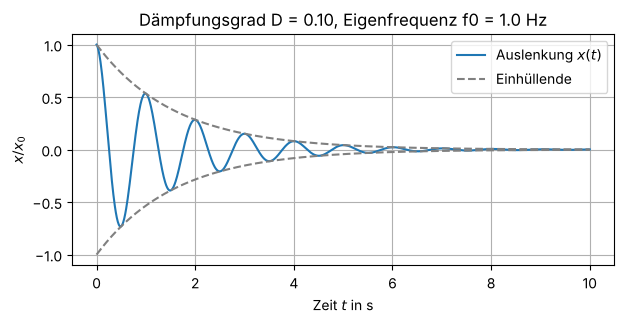

In [1]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 10, 1000)  # Zeit in s

def plot_oscillation(D=0.1, f0=1.0):
    """Zeichnet die freie Schwingung eines gedämpften Einmassenschwingers."""
    omega0 = 2 * np.pi * f0
    x = np.exp(-D * omega0 * t) * np.cos(omega0 * np.sqrt(1 - D**2) * t)
    envelope = np.exp(-D * omega0 * t)

    plt.figure(figsize=(7, 3))
    plt.plot(t, x, label="Auslenkung $x(t)$")
    plt.plot(t, envelope, "--", color="gray", label="Einhüllende")
    plt.plot(t, -envelope, "--", color="gray")
    plt.ylim(-1.1, 1.1)
    plt.xlabel("Zeit $t$ in s")
    plt.ylabel("$x / x_0$")
    plt.title(f"Dämpfungsgrad D = {D:.2f}, Eigenfrequenz f0 = {f0:.1f} Hz")
    plt.legend(loc="upper right")
    plt.grid(True)
    plt.show()

plot_oscillation(D=0.1, f0=1.0)

Um die Parameter interaktiv zu verändern, genügt eine einzige Zeile: `interact()` erhält die Funktion und für jeden Parameter einen Wertebereich `(min, max, schrittweite)`. Daraus erzeugt es automatisch Schieberegler. Bei jeder Änderung wird die Funktion mit den neuen Werten aufgerufen und das Diagramm neu gezeichnet – `plot_oscillation` ist hier also der Callback.

In [2]:
#| output: false
from ipywidgets import interact

interact(plot_oscillation, D=(0.0, 0.95, 0.05), f0=(0.2, 3.0, 0.1));  # ; unterdrückt die Textausgabe

::: {.callout-note}
### Widgets brauchen einen laufenden Python-Kernel {.unnumbered}

Die Schieberegler funktionieren nur im laufenden Notebook (Jupyter, VS Code, Colab), weil bei jeder Bewegung Python-Code ausgeführt werden muss. In der HTML- oder PDF-Version dieses Skripts sind die Regler deshalb nicht bedienbar. Die folgenden Screenshots zeigen beispielhaft, wie sich das Diagramm bei verschiedenen Reglerstellungen verändert. Probieren Sie die Zelle unbedingt selbst aus!
:::

::: {.content-visible when-format="html"}

::: {.panel-tabset}

#### D = 0,05 {.unnumbered .unlisted}

![Schwach gedämpft: Die Maschine schwingt lange nach.](images/gui-schwinger-D005.png)

#### D = 0,20 {.unnumbered .unlisted}

![Stärker gedämpft: Die Schwingung klingt nach wenigen Perioden ab.](images/gui-schwinger-D020.png)

#### D = 0,60 {.unnumbered .unlisted}

![Stark gedämpft: Es gibt kaum noch ein Überschwingen.](images/gui-schwinger-D060.png)

#### D = 0,05, f0 = 2 Hz {.unnumbered .unlisted}

![Gleiche Dämpfung, doppelte Eigenfrequenz: doppelt so viele Schwingungen, und sie klingen schneller ab.](images/gui-schwinger-D005-f2.png)

:::

:::

::: {.content-visible unless-format="html"}

::: {#fig-schwinger layout-ncol=2}

![D = 0,05, f0 = 1 Hz](images/gui-schwinger-D005.png)

![D = 0,20, f0 = 1 Hz](images/gui-schwinger-D020.png)

![D = 0,60, f0 = 1 Hz](images/gui-schwinger-D060.png)

![D = 0,05, f0 = 2 Hz](images/gui-schwinger-D005-f2.png)

Der Einmassenschwinger bei verschiedenen Reglerstellungen: Je größer der Dämpfungsgrad D, desto schneller klingt die Schwingung ab (a–c). Bei gleicher Dämpfung und doppelter Eigenfrequenz (d) schwingt die Maschine doppelt so schnell, und die Schwingung klingt ebenfalls schneller ab.

:::

:::

Je nach Datentyp des Wertebereichs wählt `interact` ein passendes Bedienelement: Zahlentupel ergeben Schieberegler, eine Liste von Strings eine Auswahlliste, `True`/`False` eine Checkbox.

## Desktop-Anwendungen mit tkinter

Für ein eigenständiges Werkzeug mit eigenem Fenster bietet sich `tkinter` an. Das Modul gehört zur Standardbibliothek von Python, muss also nicht installiert werden, und läuft unter Windows, macOS und Linux.

::: {.callout-important}
### tkinter-Programme als Skript ausführen {.unnumbered}

Ein tkinter-Fenster öffnet sich auf dem Rechner, auf dem Python läuft – in Google Colab also nicht. In einem lokalen Notebook bleibt die Zelle blockiert, bis Sie das Fenster schließen. Speichern Sie die Beispiele daher als `.py`-Datei und starten Sie sie z.B. in Spyder, VS Code oder mit `python dateiname.py`. Im Skript werden diese Zellen nicht ausgeführt; stattdessen sehen Sie einen Screenshot.
:::

### Beispiel: ein Biegespannungsrechner {.unnumbered}

Als Beispiel bauen wir einen Rechner für die Biegespannung in einem Balken mit Rechteckquerschnitt, $\sigma = 6 M / (b h^2)$ (vgl. Anhang B). Die Berechnung steckt in einer eigenen Funktion. Der Callback liest die Eingabefelder (`Entry`) mit `get()` als **String** aus, wandelt die Eingaben um (deutsches Dezimalkomma inklusive) und zeigt das Ergebnis an. Ungültige Eingaben fangen wir mit `try`/`except` ab und melden sie in einem Dialogfenster (`messagebox`), statt das Programm abstürzen zu lassen:

In [ ]:
#| eval: false
import tkinter as tk
from tkinter import messagebox


def bending_stress_rect(moment_Nmm, width_mm, height_mm):
    """Biegespannung in N/mm² (MPa) für einen Rechteckquerschnitt."""
    if width_mm <= 0 or height_mm <= 0:
        raise ValueError("Breite und Höhe müssen positiv sein.")
    return 6 * moment_Nmm / (width_mm * height_mm**2)


def on_calculate():
    """Callback: wird bei jedem Klick auf den Button aufgerufen."""
    try:
        moment = float(entry_moment.get().replace(",", ".")) * 1000  # Nm -> Nmm
        width = float(entry_width.get().replace(",", "."))
        height = float(entry_height.get().replace(",", "."))
        sigma = bending_stress_rect(moment, width, height)
    except ValueError as e:
        messagebox.showerror("Ungültige Eingabe", str(e))
        return
    label_result.config(text=f"σ = {sigma:.1f} MPa")


window = tk.Tk()
window.title("Biegespannungsrechner")

# Beschriftungen und Eingabefelder in einem Raster (grid) anordnen
tk.Label(window, text="Biegemoment M [Nm]:").grid(row=0, column=0, sticky="w", padx=10, pady=5)
tk.Label(window, text="Breite b [mm]:").grid(row=1, column=0, sticky="w", padx=10, pady=5)
tk.Label(window, text="Höhe h [mm]:").grid(row=2, column=0, sticky="w", padx=10, pady=5)

entry_moment = tk.Entry(window, width=12)
entry_width = tk.Entry(window, width=12)
entry_height = tk.Entry(window, width=12)
entry_moment.grid(row=0, column=1, padx=10)
entry_width.grid(row=1, column=1, padx=10)
entry_height.grid(row=2, column=1, padx=10)

button = tk.Button(window, text="Berechnen", command=on_calculate)
button.grid(row=3, column=0, columnspan=2, pady=10)

label_result = tk.Label(window, text="σ = ?", font=("Arial", 14, "bold"))
label_result.grid(row=4, column=0, columnspan=2, pady=(0, 10))

window.mainloop()

![Der Biegespannungsrechner nach einem Klick auf „Berechnen“.](images/gui-biegespannung.png)

Jedes tkinter-Programm folgt demselben Grundmuster:

- **Hauptfenster und Widgets erzeugen:** `tk.Tk()` erzeugt das Fenster; jedes Widget erhält beim Erzeugen als erstes Argument das Fenster, in dem es liegen soll.
- **Widgets platzieren:** Ein erzeugtes Widget ist noch unsichtbar. Erst ein Geometriemanager platziert es: `grid()` ordnet in Zeilen und Spalten an, `pack()` stapelt einfach untereinander. `sticky="w"` richtet links (*west*) aus, `padx`/`pady` legen Abstände in Pixeln fest.
- **Callback registrieren:** `command=on_calculate` übergibt die **Funktion selbst, ohne Klammern**. Mit `command=on_calculate()` würde Python sie sofort beim Erzeugen des Buttons aufrufen, statt sie für den Klick zu hinterlegen – ein typischer Anfängerfehler!
- **Ereignisschleife starten:** `mainloop()` kehrt erst zurück, wenn das Fenster geschlossen wird; Code danach läuft also erst am Programmende.

Mit `label_result.config(text=...)` ändert der Callback die Beschriftung eines bestehenden Widgets nachträglich.

## Weitere Werkzeuge

tkinter ist schlicht, aber für kleine Werkzeuge völlig ausreichend. Für umfangreiche Desktop-Anwendungen (z.B. Mess- und Steuersoftware) sind **PyQt** bzw. **PySide** verbreitet; Auswertewerkzeuge und Dashboards im Browser lassen sich mit **Streamlit**, **Dash** oder **Panel** mit wenig Code erstellen.

<div class="exercises">
<b>Übungen:</b>

1. Erweitern Sie `plot_oscillation` um einen Parameter `x0` für die Anfangsauslenkung und ergänzen Sie einen passenden Schieberegler. Passen Sie auch die y-Achse an.
2. Schreiben Sie mit tkinter einen Rechner für das ohmsche Gesetz: Spannung $U$ und Strom $I$ werden eingegeben, nach einem Klick auf einen Button wird der Widerstand $R = U / I$ angezeigt. Ungültige Eingaben und $I = 0$ sollen mit einer verständlichen Meldung abgefangen werden.

</div>

In [ ]:
#| code-fold: true
#| eval: false
# Übung 1 (im Notebook ausführen)
def plot_oscillation(D=0.1, f0=1.0, x0=1.0):
    omega0 = 2 * np.pi * f0
    envelope = x0 * np.exp(-D * omega0 * t)
    x = envelope * np.cos(omega0 * np.sqrt(1 - D**2) * t)
    plt.figure(figsize=(7, 3))
    plt.plot(t, x, label="Auslenkung $x(t)$")
    plt.plot(t, envelope, "--", color="gray", label="Einhüllende")
    plt.plot(t, -envelope, "--", color="gray")
    plt.ylim(-5.5, 5.5)  # fest, damit man die Änderung von x0 sieht
    plt.xlabel("Zeit $t$ in s")
    plt.ylabel("$x$ in mm")
    plt.legend(loc="upper right")
    plt.grid(True)
    plt.show()

interact(plot_oscillation, D=(0.0, 0.95, 0.05), f0=(0.2, 3.0, 0.1), x0=(0.5, 5.0, 0.5));

# Übung 2 (als .py-Datei speichern und ausführen)
import tkinter as tk
from tkinter import messagebox


def on_calculate():
    try:
        voltage = float(entry_u.get().replace(",", "."))
        current = float(entry_i.get().replace(",", "."))
        resistance = voltage / current
    except ValueError:
        messagebox.showerror("Ungültige Eingabe", "Bitte Zahlen für U und I eingeben.")
        return
    except ZeroDivisionError:
        messagebox.showerror("Ungültige Eingabe", "Der Strom darf nicht 0 sein.")
        return
    label_result.config(text=f"R = {resistance:.2f} Ω")


window = tk.Tk()
window.title("Ohmsches Gesetz")

tk.Label(window, text="Spannung U [V]:").grid(row=0, column=0, sticky="w", padx=10, pady=5)
tk.Label(window, text="Strom I [A]:").grid(row=1, column=0, sticky="w", padx=10, pady=5)
entry_u = tk.Entry(window, width=12)
entry_i = tk.Entry(window, width=12)
entry_u.grid(row=0, column=1, padx=10)
entry_i.grid(row=1, column=1, padx=10)

tk.Button(window, text="R berechnen", command=on_calculate).grid(row=2, column=0, columnspan=2, pady=10)
label_result = tk.Label(window, text="R = ?", font=("Arial", 14, "bold"))
label_result.grid(row=3, column=0, columnspan=2, pady=(0, 10))

window.mainloop()